# Task 29: Relationship Analysis

**Internship Track:** AI & ML  
**Task Number:** 29  
**Topic:** Relationship Analysis  
**Tools Used:** Python, Pandas, Matplotlib, Jupyter Notebook  
**Dataset:** Iris Dataset

## Objective
Create a scatter plot to analyze the relationship between two numerical variables and describe the observed pattern.

## Description
In this task, we use data visualization to understand the relationship between two numerical variables. A scatter plot is created using Matplotlib to identify positive, negative, or weak relationships between variables.

## Deliverables
- Scatter plot
- Description of the relationship
- At least three observations
- Answers to the interview questions

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

## 1. Dataset Introduction

The Iris dataset is a commonly used dataset in machine learning and data analysis. It contains measurements of iris flowers from three species: Setosa, Versicolor, and Virginica.

The dataset includes four numerical features:
- Sepal length
- Sepal width
- Petal length
- Petal width

In this task, petal length and petal width are selected to study their relationship using a scatter plot.

In [2]:
iris = load_iris(as_frame=True)

df = iris.frame

df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

df = df.drop(columns=["target"])

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst Five Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (150, 5)

Column Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']

First Five Rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicate Rows:
1


## 2. Selection of Numerical Variables

Two numerical variables are selected for relationship analysis:

- **X-axis:** Petal Length (cm)
- **Y-axis:** Petal Width (cm)

These variables are selected because comparing their measurements helps us understand whether flowers with longer petals also tend to have wider petals.

In [5]:
x = df["petal length (cm)"]
y = df["petal width (cm)"]

print("X Variable: Petal Length (cm)")
print("Y Variable: Petal Width (cm)")

print("\nPetal Length Statistics:")
print(x.describe())

print("\nPetal Width Statistics:")
print(y.describe())

X Variable: Petal Length (cm)
Y Variable: Petal Width (cm)

Petal Length Statistics:
count    150.000000
mean       3.758000
std        1.765298
min        1.000000
25%        1.600000
50%        4.350000
75%        5.100000
max        6.900000
Name: petal length (cm), dtype: float64

Petal Width Statistics:
count    150.000000
mean       1.199333
std        0.762238
min        0.100000
25%        0.300000
50%        1.300000
75%        1.800000
max        2.500000
Name: petal width (cm), dtype: float64


## 3. Scatter Plot

A scatter plot represents two numerical variables using individual points. Each point corresponds to one flower in the dataset.

The plot helps us identify the direction, strength, and overall pattern of the relationship between petal length and petal width.

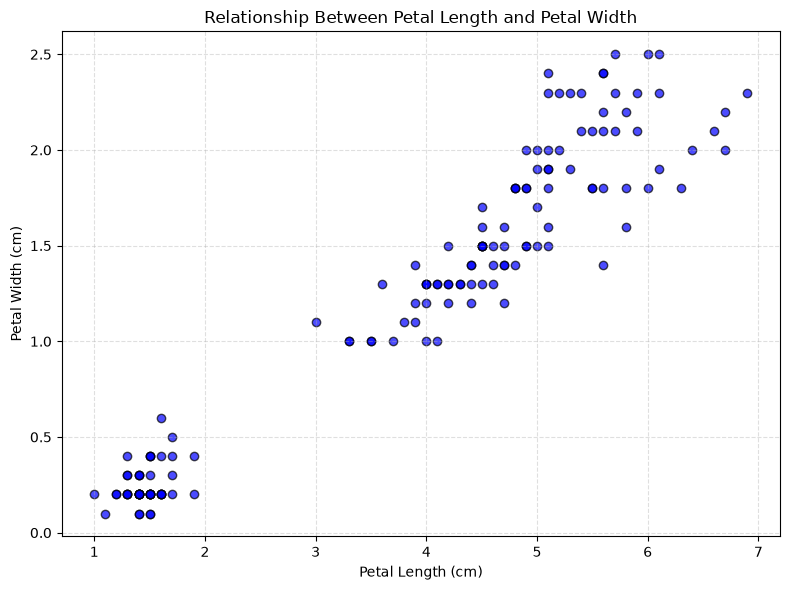

In [6]:
plt.figure(figsize=(8, 6))

plt.scatter(
    x,
    y,
    color="blue",
    alpha=0.7,
    edgecolors="black"
)

plt.title("Relationship Between Petal Length and Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 4. Scatter Plot by Species

To improve the visualization, different colors are used to represent the three Iris species. This makes it easier to identify clusters and compare their petal measurements.

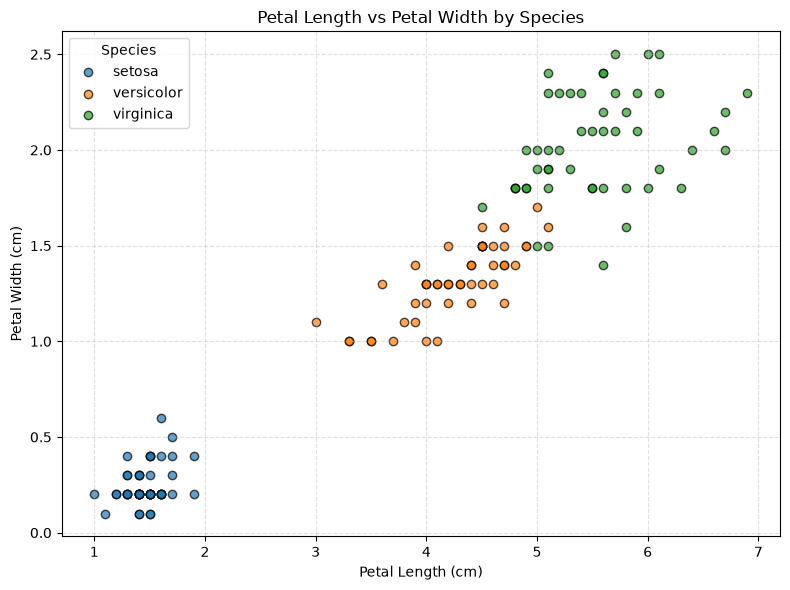

In [7]:
plt.figure(figsize=(8, 6))

for species in df["species"].unique():
    subset = df[df["species"] == species]

    plt.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=species,
        alpha=0.7,
        edgecolors="black"
    )

plt.title("Petal Length vs Petal Width by Species")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.legend(title="Species")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 5. Correlation Analysis

Correlation measures the strength and direction of the linear relationship between two numerical variables.

The Pearson correlation coefficient ranges from -1 to +1:

- **+1:** Perfect positive linear relationship
- **0:** No linear correlation
- **-1:** Perfect negative linear relationship

A positive coefficient indicates that the variables tend to increase together. Correlation alone does not establish causation.

In [8]:
correlation = df["petal length (cm)"].corr(
    df["petal width (cm)"]
)

print("Correlation Coefficient:", round(correlation, 3))

if correlation > 0:
    print("Relationship: Positive")
elif correlation < 0:
    print("Relationship: Negative")
else:
    print("Relationship: No Linear Correlation")

Correlation Coefficient: 0.963
Relationship: Positive


In [9]:
print("Correlation by Species:\n")

for species in df["species"].unique():
    subset = df[df["species"] == species]

    value = subset["petal length (cm)"].corr(
        subset["petal width (cm)"]
    )

    print(f"{species.capitalize()}: {value:.3f}")

Correlation by Species:

Setosa: 0.332
Versicolor: 0.787
Virginica: 0.322
